# TÓPICOS DE MATEMÁTICA PARA SISTEMAS AUTÓNOMOS
## TRABALHO LETIVO - ENTREGA 2

**Visualização de trajetórias e referenciais de vários robôs**  
ISEP · Mestrado em Engenharia Eletrotécnica e de Computadores · Sistemas Autónomos  
**Grupo 07 · Aplicação v0.4 · 29 de outubro de 2026**

---

**Nota 1:** Todos os elementos do grupo são responsáveis por esta entrega.  
**Nota 2:** Todos os elementos do grupo tomaram conhecimento das regras estabelecidas para o funcionamento da UC no [Moodle do ISEP](https://moodle.isep.ipp.pt).

Este relatório apresenta a implementação, os resultados obtidos com os registos reais e as limitações que condicionam a sua interpretação. As tabelas e figuras calculadas já estão guardadas no notebook. Os dados e os resultados derivados destinam-se à utilização na UC TOMSA, nos termos do README fornecido com os logs.

## GRUPO 07

| Número de aluno | Nome |
|---|---|
| 1221309 | Henrique Correia |
| 1231177 | Pedro Ribeiro |
| 1231216 | Francisco Liquito |

<a id="conteudo"></a>
# Conteúdo

1. [Análise crítica dos objetivos definidos versus objetivos atingidos](#objetivos)
2. [Descrição do código implementado e justificação das bibliotecas](#codigo)
3. [Resultados e evidências](#resultados)
4. [Análise crítica do trabalho da equipa](#equipa)

[Referências](#referencias)

<a id="objetivos"></a>
## 1. Análise crítica dos objetivos definidos versus objetivos atingidos

[Voltar ao conteúdo](#conteudo)

Na primeira entrega propusemos construir um dashboard Python/Dash para reproduzir uma missão com três robôs, comparar posições num referencial comum e num referencial relativo ao robô selecionado, configurar os parâmetros em YAML e exportar os resultados. Estes objetivos correspondem às funcionalidades do enunciado [1]. A versão desenvolvida utiliza os três CSV originais do ZIP da UC; a demonstração sintética é um modo separado, identificado na interface.

| Objetivo definido | Implementação e evidência | Balanço crítico |
|---|---|---|
| Vista global com trajetórias, posições e cores por robô | Vistas cartesianas NED 2D/3D e mapa com latitude/longitude originais; Figuras 1 e 4. | Concluído para as posições. As setas de orientação nas vistas cartesianas mantêm a identificação de hipótese quando a convenção não está confirmada. |
| Vista local do robô escolhido e vizinhos próximos | Subtração da posição do centro, rotação inversa quando utilizável e filtro pela distância NED 3D; Figura 2 e tabelas do snapshot. | Concluído sob condições explícitas. Para o robô 7, sem orientação utilizável, aplica-se apenas translação. Não se apresenta esta vista como orientação corporal comprovada. |
| Replay sincronizado, Play/Pause e salto temporal | Slider comum, passo de 0,5 s, amostra mais próxima até ±0,3 s e paragem no fim; auditoria de 4 794 instantes. | Concluído. Não há interpolação; os tempos efetivos das três amostras podem diferir. |
| Configuração YAML | Ficheiros, nomes/cores, origem geográfica, passo, tolerância, proximidade e estados de confirmação definidos no YAML. | Concluído. As hipóteses são configuráveis e não ficam escondidas nos gráficos. |
| Registo e configuração de saída | CSV NED/cinemática, CSV do snapshot local e YAML efetivo da sessão. | Concluído. Valores não disponíveis ficam vazios e o referencial usado é identificado. |
| Organização, testes e explicação dos cálculos | Módulos separados, testes automatizados e painel «Mostrar a matemática». | Concluído no âmbito de um protótipo académico local; não foi validado como sistema de navegação ou serviço de produção. |

Acrescentámos medições AER, análise da norma da velocidade e da sua derivada temporal, cartografia OpenSeaMap, rastos recentes e uma comparação interativa de transformações rígidas. Estas extensões tornam o resultado mais fácil de explorar e de defender matematicamente, sem substituir os objetivos iniciais.

O principal desvio face à proposta é a impossibilidade de confirmar toda a interpretação física das orientações apenas pelos ficheiros recebidos. O README documenta latitude, longitude e altitude, mas não fixa os eixos do corpo, o sentido do quaternião ou a base das velocidades. Optámos por identificar a hipótese `world_ned`, permitir desligá-la e impedir o rumo geográfico e a aceleração vetorial quando não existe confirmação. Assim, o resultado é funcional e verificável, mas a interpretação corporal completa permanece condicionada a esclarecimento do produtor/docente.

<a id="codigo"></a>
## 2. Descrição do código implementado e justificação das bibliotecas

[Voltar ao conteúdo](#conteudo)

### 2.1. Organização e fluxo de execução

A aplicação segue o fluxo **YAML e ZIP → validação → coordenadas/cinemática → estado temporal → gráficos/exportações**. Os dados são carregados uma vez. Cada ação do utilizador seleciona um instante e um robô de referência; as vistas usam o mesmo conjunto de amostras desse instante.

| Ficheiro/módulo | Responsabilidade |
|---|---|
| `app.py` | Layout Dash, callbacks, controlo temporal, painel matemático e downloads. |
| `tomsa/data.py` | Leitura do YAML e ZIP, validação, normalização dos quaterniões e construção da missão. |
| `tomsa/coordinates.py` | WGS84/ECEF/NED, transformações corpo-mundo, AER e cálculo condicionado do rumo. |
| `tomsa/replay.py` | Pesquisa da amostra mais próxima, snapshot comum, posições relativas e invariantes rígidos. |
| `tomsa/kinematics.py` | Norma da velocidade e diferenciação com tempos não uniformes e separação de lacunas. |
| `tomsa/figures.py` | Vistas NED/local, comparação 3D e gráficos de cinemática. |
| `tomsa/geography.py` | Trajetórias estáticas e poses atuais para o mapa. |
| `assets/geography.js`, `map_geometry.js`, `ocean.js`, `style.css` | MapLibre, marcadores, rastos, círculo horizontal e apresentação. |
| `tests/` | Testes de coordenadas, tempo, referenciais, cinemática, figuras, callbacks, exportações e JavaScript. |

A leitura conserva os timestamps em nanossegundos inteiros e ordena os registos. Faltas em colunas obrigatórias, timestamps duplicados e quaterniões nulos produzem mensagens de erro; registos com campos numéricos obrigatórios não finitos são excluídos. Valores opcionais de velocidade inválidos ficam indisponíveis sem eliminar uma pose válida. As coordenadas geográficas originais são conservadas para o mapa.

### 2.2. Bibliotecas selecionadas

| Biblioteca | Utilização efetiva e justificação |
|---|---|
| pandas | Leitura dos CSV, seleção/validação de colunas e preparação das tabelas e exportações. Evita parsing manual dos registos. |
| NumPy | Vetores, matrizes, normas, mudanças de base e diferenças temporais. `gradient` aceita as coordenadas temporais reais, incluindo espaçamento não uniforme [5]. |
| SciPy | `Rotation` representa e aplica rotações a partir de quaterniões, evitando implementar manualmente toda a álgebra de conversão [4]. |
| Plotly | Gráficos 2D/3D interativos, hover e manutenção da exploração da vista. |
| Dash | Interface em Python, ligação entre propriedades de controlos e gráficos através de callbacks [6], replay e downloads. |
| PyYAML | Leitura e escrita de configuração legível, separada do código. |
| pytest | Verificação automática de exemplos conhecidos, invariantes, indisponibilidades, callbacks e exportações. |
| Matplotlib | Figuras estáticas deste relatório. Na aplicação, os gráficos continuam a usar Plotly. |

`pathlib`, `zipfile`, `dataclasses` e `itertools` pertencem à biblioteca padrão. MapLibre GL JS é a biblioteca JavaScript do mapa; OpenStreetMap e OpenSeaMap fornecem cartografia, não são bibliotecas Python. Os testes JavaScript usam o executor nativo de Node, quando disponível. A implementação não requer um frontend separado com npm.

### 2.3. Tempo e mudança de coordenadas

Para cada registo usamos o timestamp original da mensagem:

$$t_{ns}=10^9\,\mathrm{secs}+\mathrm{nsecs}.$$

O slider percorre a interseção dos três períodos de registo. Para um instante $t$, escolhe-se $j=\arg\min_i|t_i-t|$, aceitando a amostra apenas se $|t_j-t|\leq0,3$ s. Se não existir, o robô fica indisponível. A época é subtraída em inteiros antes de converter diferenças para segundos, reduzindo perdas de precisão. Este alinhamento pressupõe relógios comparáveis, mas não comprova sincronização física.

Segundo o README [2], `position.x/y` são latitude/longitude em graus e `position.z` é altitude em metros, mesmo quando o identificador é `world_ned`. Por isso não se podem tratar os valores originais como metros cartesianos. Para latitude $\varphi$, longitude $\lambda$ em radianos e altura $h$, usamos o elipsoide WGS84, com $a=6\,378\,137$ m, $f=1/298,257223563$ e $e^2=f(2-f)$:

$$\nu(\varphi)=\frac{a}{\sqrt{1-e^2\sin^2\varphi}},\qquad
p_E=\begin{bmatrix}(\nu+h)\cos\varphi\cos\lambda\\(\nu+h)\cos\varphi\sin\lambda\\(\nu(1-e^2)+h)\sin\varphi\end{bmatrix}.$$

Depois, relativamente à origem fixa $(\varphi_0,\lambda_0,h_0)$ do YAML:

$$p_N=C(p_E-p_{E0}),\qquad
C=\begin{bmatrix}
-\sin\varphi_0\cos\lambda_0&-\sin\varphi_0\sin\lambda_0&\cos\varphi_0\\
-\sin\lambda_0&\cos\lambda_0&0\\
-\cos\varphi_0\cos\lambda_0&-\cos\varphi_0\sin\lambda_0&-\sin\varphi_0
\end{bmatrix}.$$

$p_N=(N,E,D)^T$ tem unidades de metro: Norte, Este e Baixo. Trata-se de uma base cartesiana fixa tangente na origem, não de uma distância percorrida sobre a superfície. A cadeia geodésicas → geocêntricas → topocêntricas é também descrita pelo PROJ [7]; na nossa implementação a última base é NED, em vez de ENU.

**Limitação vertical:** o README refere altitude acima do nível do mar, sem confirmar altura elipsoidal. A conversão mantém a hipótese de alturas comparáveis já declarada no projeto; não foi aplicada uma correção geoidal sem dados que a justificassem. Isto limita a interpretação de Down e das grandezas 3D derivadas.

### 2.4. Quaterniões, transformações rígidas e invariantes

Os quaterniões são lidos em $(x,y,z,w)$ e normalizados. Esta é a ordem escalar no fim usada por defeito em `Rotation.from_quat` [4]. Contudo, a ordem dos componentes não resolve, por si só, os eixos e o sentido físico da rotação do produtor.

Admitindo que $R=R(q)$ transforma coordenadas do corpo selecionado para NED e que $p_0$ é a sua posição, a transformação local é

$$p_L=R^T(p_N-p_0),\qquad p_N=Rp_L+p_0.$$

Em coordenadas homogéneas, com $\widetilde p=(p^T,1)^T$:

$$\widetilde p_N=T_{N\leftarrow L}\widetilde p_L,\qquad
T_{N\leftarrow L}=\begin{bmatrix}R&p_0\\0&1\end{bmatrix},\qquad
T_{L\leftarrow N}=\begin{bmatrix}R^T&-R^Tp_0\\0&1\end{bmatrix}.$$

Como $R^TR=I$ e $\det R=+1$, $T$ é uma transformação rígida própria, pertencente a $SE(3)$. Para dois pontos do mesmo snapshot:

$$\|p_{L,i}-p_{L,j}\|^2=(p_{N,i}-p_{N,j})^TRR^T(p_{N,i}-p_{N,j})=\|p_{N,i}-p_{N,j}\|^2.$$

Verificamos a origem do centro, ortogonalidade, determinante, reconstrução pela inversa e distâncias 3D antes de arredondar os valores. **Uma transformação algebricamente válida não comprova a orientação física dos logs.** Uma projeção 2D também pode alterar a forma aparente de um triângulo rígido; por isso o painel compara cenas e normas em 3D.

Nos dados reais, `world_ned` nos robôs 1/4 permite apenas a hipótese configurada, identificada como `robot_body_assumed`. Para o robô 7, `WGS84` não define eixos do corpo: usa-se $R=I$, ficando `ned_translated`. O estado `robot_body_confirmed` exige confirmação externa. A hipótese pode ser desligada no YAML. O percurso local inteiro é expresso na base do centro no instante selecionado; não se roda cada ponto histórico pela sua própria orientação.

O filtro de proximidade usa $\|p_N-p_0\|\leq r$ em 3D. As observações AER são calculadas diretamente da diferença NED, independentemente do quaternião:

$$\rho=\sqrt{N^2+E^2+D^2},\quad
az=\operatorname{atan2}(E,N)\pmod{2\pi},\quad
el=\operatorname{atan2}(-D,\sqrt{N^2+E^2}).$$

O azimute parte do Norte no sentido horário e a elevação é positiva para cima. Na origem, os ângulos são indefinidos e não são inventados.

### 2.5. Cinemática e interpretação das derivadas

A rapidez é calculada a partir das componentes de velocidade registadas:

$$s(t)=\|v(t)\|=\sqrt{v_x^2+v_y^2+v_z^2}.$$

A norma é invariante sob rotações entre bases ortonormais com as mesmas unidades. O README descreve as unidades como «normalmente» m/s e rad/s; apresentamos a interpretação SI usual sem a transformar numa confirmação da convenção do produtor. Não derivamos latitude/longitude para gerar velocidades alternativas.

Distinguimos a derivada assinada $ds/dt$ da magnitude da aceleração vetorial $\|dv_{NED}/dt\|$. Para $s>0$, $ds/dt$ é a componente tangencial; um valor negativo indica redução da rapidez. Numa curva a rapidez constante pode existir aceleração normal mesmo com $ds/dt=0$. No ponto $s=0$, a direção tangente não fica definida por esta expressão.

A diferenciação usa os tempos reais não uniformes. Em cada segmento com pelo menos três amostras, para $h_s=t_i-t_{i-1}$ e $h_d=t_{i+1}-t_i$, o esquema interior é [5]:

$$s'_i\approx-\frac{h_d}{h_s(h_s+h_d)}s_{i-1}
+\frac{h_d-h_s}{h_sh_d}s_i
+\frac{h_s}{h_d(h_s+h_d)}s_{i+1}.$$

Nos extremos usam-se diferenças unilaterais de segunda ordem; com duas amostras, a secante; uma amostra isolada fica indisponível. Valores não finitos, intervalos não positivos e lacunas superiores a 2 s separam segmentos. Não há suavização, pelo que a derivada pode amplificar ruído.

Diferenciar componentes numa base corporal em rotação não fornece diretamente aceleração numa base fixa. Se a convenção fosse confirmada, seria necessário obter primeiro $v_{NED}(t)=R(t)v_{body}(t)$ e só depois derivar, incluindo a variação da base. Como a confirmação não existe nos logs reais, a aceleração vetorial permanece indisponível. A demo conhecida e os testes sintéticos permitem verificar essa implementação sem atribuir aos dados reais uma convenção desconhecida.

### 2.6. Apresentação, configuração e exportação

O mapa recebe trajetórias completas e tempos relativos uma vez; o replay envia poses, índices e raio. Os rastos de 30/60 s ligam amostras originais até à amostra atual, sem interpolar nem unir lacunas grandes. A instância e a câmara MapLibre são conservadas. Nos gráficos cinemáticos, o cursor é atualizado parcialmente com Dash `Patch`.

Os ícones, o brilho e o pulso são apresentação. O círculo do mapa é horizontal e usa uma aproximação esférica com raio médio terrestre de 6 371 008,8 m; não substitui o filtro NED 3D nem representa alcance medido de um sensor. O oceano animado usa sombreado de uma superfície plana, recortado por polígonos de água: não representa ondas medidas, batimetria ou altitude dos veículos. No mapa, só se mostra seta de rumo com corpo → NED fixo confirmado; por defeito não há setas nos logs reais.

As exportações incluem os tempos, o robô e o referencial efetivamente utilizado. O CSV NED acrescenta rapidez e derivadas disponíveis; o snapshot local distingue hipótese corporal de NED transladado. O YAML exportado corresponde à configuração efetiva, incluindo uma eventual opção de demo. Assim, o resultado pode ser interpretado sem depender apenas do aspeto do gráfico.

<a id="resultados"></a>
## 3. Resultados e evidências

[Voltar ao conteúdo](#conteudo)

Os resultados seguintes foram recalculados com o ZIP real, utilizando as funções da aplicação, em 29/10/2026. A data das mensagens é **10/10/2025**, conforme os timestamps; não é a data da análise. As figuras analíticas mostram o intervalo comum, salvo o gráfico de cobertura que apresenta a duração completa de cada log.

**Reprodução dos cálculos:** para ler basta abrir este notebook, pois os resultados estão guardados. Para executar novamente, colocar o notebook ao lado da pasta `TOMSA_Grupo07_v03`, instalar as dependências do projeto e `matplotlib`, e disponibilizar o ZIP em `TOMSA_Grupo07_v03/data/TL2026.zip` ou ao lado do notebook. O caminho de `PROJECT_DIR` na primeira célula pode ser ajustado. Não se exige executar o servidor Dash para reproduzir os cálculos.

In [1]:
from pathlib import Path
from zipfile import ZipFile
from copy import deepcopy
import sys, math, subprocess, hashlib, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Markdown

get_ipython().run_line_magic('matplotlib', 'inline')
plt.rcParams.update({'figure.dpi': 130, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .2})
pd.set_option('display.max_colwidth', 90)

PROJECT_DIR = Path('TOMSA_Grupo07_v03').resolve()
if not (PROJECT_DIR / 'tomsa' / 'data.py').is_file():
    raise FileNotFoundError('Ajustar PROJECT_DIR para a pasta da aplicacao TOMSA_Grupo07_v03.')
sys.path.insert(0, str(PROJECT_DIR))
from tomsa.data import load_config, load_mission, STAMP_COLS, POS_COLS, QUAT_COLS
from tomsa.replay import mission_state, frame_diagnostics, relative_aer

cfg = deepcopy(load_config(PROJECT_DIR / 'config.yaml'))
cfg['data']['mode'] = 'zip'
zip_path = PROJECT_DIR / 'data' / 'TL2026.zip'
if not zip_path.is_file():
    zip_path = Path('TL2026.zip').resolve()
cfg['data']['zip_path'] = str(zip_path)
mission = load_mission(cfg, PROJECT_DIR)
mission.source = mission.source.replace(chr(0x2014), '-').replace(chr(0x2013), '-')
assert 'DADOS REAIS' in mission.source
keys = list(mission.traces)
colors = {k: mission.traces[k].color for k in keys}
masks = {k: (tr.times_ns >= mission.start_ns) & (tr.times_ns <= mission.end_ns)
         for k, tr in mission.traces.items()}

def tabela(frame, decimals=3):
    html = frame.to_html(index=False, border=0, float_format=lambda x: f'{x:.{decimals}f}')
    display(HTML('<div class="report-table">' + html + '</div>'))

def utc(ns):
    return pd.to_datetime(int(ns), unit='ns', utc=True).strftime('%d/%m/%Y %H:%M:%S')

print(mission.source)
print(f'Intervalo comum: {utc(mission.start_ns)} a {utc(mission.end_ns)} UTC')
print(f'Duração: {mission.duration_s:.9f} s = {mission.duration_s/60:.5f} min')

DADOS REAIS - ZIP fornecido para a UC
Intervalo comum: 10/10/2025 12:00:00 a 10/10/2025 12:39:56 UTC
Duração: 2396.191938162 s = 39.93653 min


### 3.1. Caracterização dos dados e trajetórias

Foram lidos **30 152 registos**, com 21 colunas por CSV: 9 537 do robô 1, 5 615 do robô 4 e 15 000 do robô 7. Não foram encontrados valores em falta, timestamps duplicados ou inversões temporais nos ficheiros originais. Os campos numéricos obrigatórios verificados são finitos e todos os registos foram conservados. As normas originais dos quaterniões estão próximas de 1 à precisão de ponto flutuante.

In [2]:
quality, periods, norm_errors = [], [], []
with ZipFile(zip_path) as archive:
    for key, trace in mission.traces.items():
        filename = cfg['data']['files'][key]
        entry = next(n for n in archive.namelist() if Path(n).name == filename)
        raw = pd.read_csv(archive.open(entry))
        stamps = raw[STAMP_COLS].to_numpy(dtype=np.int64)
        ns = stamps[:, 0]*1_000_000_000 + stamps[:, 1]
        numeric = raw[STAMP_COLS + POS_COLS + QUAT_COLS].to_numpy(dtype=float)
        norm_errors.append(float(np.max(np.abs(np.linalg.norm(raw[QUAT_COLS], axis=1)-1))))
        dt = np.diff(ns)/1e9
        quality.append({'Robô': trace.label, 'Registos': len(raw), 'Colunas': len(raw.columns),
            'Em falta': int(raw.isna().sum().sum()), 'Duplicados': int((np.diff(np.sort(ns)) == 0).sum()),
            'Inversões': int((np.diff(ns) < 0).sum()),
            'Não finitos*': int((~np.isfinite(numeric)).sum()),
            'dt min (s)': dt.min(), 'dt mediano (s)': np.median(dt), 'dt max (s)': dt.max()})
        periods.append({'Robô': trace.label, 'Início UTC': utc(ns[0]), 'Fim UTC': utc(ns[-1]),
                        'Duração (min)': (int(ns[-1])-int(ns[0]))/60e9})
        assert len(raw) == len(trace.times_ns)
tabela(pd.DataFrame(quality), 6)
print('* Campos numericos de tempo, posicao e quaternion.')
tabela(pd.DataFrame(periods))
print(f'Maior desvio original da norma dos quaternioes face a 1: {max(norm_errors):.3e}')

Robô,Registos,Colunas,Em falta,Duplicados,Inversões,Não finitos*,dt min (s),dt mediano (s),dt max (s)
Robô 1,9537,21,0,0,0,0,0.479975,0.520013,0.600007
Robô 4,5615,21,0,0,0,0,0.479994,0.520013,0.560066
Robô 7,15000,21,0,0,0,0,0.479975,0.520016,0.561338


* Campos numericos de tempo, posicao e quaternion.


Robô,Início UTC,Fim UTC,Duração (min)
Robô 1,10/10/2025 12:00:00,10/10/2025 13:24:49,84.831
Robô 4,10/10/2025 11:50:00,10/10/2025 12:39:56,49.922
Robô 7,10/10/2025 11:30:00,10/10/2025 13:43:33,133.544


Maior desvio original da norma dos quaternioes face a 1: 2.220e-16


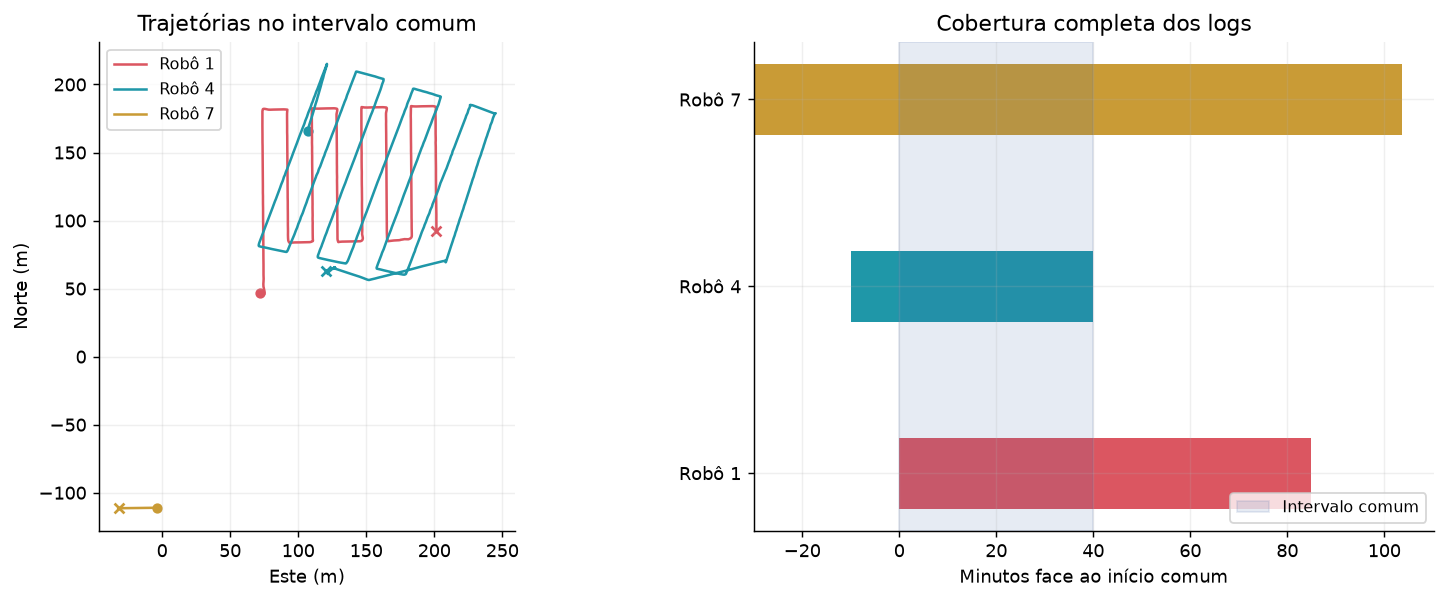

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.5), layout='constrained',
                         gridspec_kw={'width_ratios': [1.05, 1]})
for key, trace in mission.traces.items():
    p = trace.positions_ned[masks[key]]
    axes[0].plot(p[:, 1], p[:, 0], color=trace.color, label=trace.label, linewidth=1.4)
    axes[0].scatter(p[0, 1], p[0, 0], color=trace.color, marker='o', s=22)
    axes[0].scatter(p[-1, 1], p[-1, 0], color=trace.color, marker='x', s=30)
axes[0].set(xlabel='Este (m)', ylabel='Norte (m)', title='Trajetórias no intervalo comum')
axes[0].set_aspect('equal', adjustable='box')
axes[0].legend(loc='best', fontsize=9)
for row, (key, trace) in enumerate(mission.traces.items()):
    start = (int(trace.times_ns[0])-mission.start_ns)/60e9
    width = (int(trace.times_ns[-1])-int(trace.times_ns[0]))/60e9
    axes[1].barh(row, width, left=start, height=.38, color=trace.color)
axes[1].axvspan(0, mission.duration_s/60, color='#4568a8', alpha=.13, label='Intervalo comum')
axes[1].set(yticks=range(len(keys)), yticklabels=[mission.traces[k].label for k in keys],
            xlabel='Minutos face ao início comum', title='Cobertura completa dos logs')
axes[1].legend(loc='lower right', fontsize=9)
fig.savefig('tomsa-relatorio-fig1.png', dpi=170, bbox_inches='tight')
plt.show()

**Figura 1.** Trajetórias no plano NED durante o intervalo comum (círculo: primeira amostra; cruz: última) e cobertura temporal completa dos três ficheiros. O sombreado identifica a interseção usada pelo replay. A escala dos dois eixos do plano é igual; o gráfico não representa a componente Down.

O período comum tem **2 396,191938162 s (39,93653 min)**, de 12:00:00,093045711 a 12:39:56,284983873 UTC de 10/10/2025. Os intervalos medianos de amostragem são aproximadamente 0,52 s. Isto justifica procurar amostras pelo tempo, em vez de associar linhas com o mesmo índice. O robô 7 apresenta uma extensão espacial bastante menor neste período; essa observação não depende de interpretar a sua orientação.

### 3.2. Alinhamento temporal e auditoria dos referenciais

A célula seguinte percorre todos os instantes do slider, incluindo o fim exato da missão, e repete os diagnósticos para cada um dos três centros. A tolerância de aceitação é individual: ±0,3 s em relação ao slider. Dois robôs aceites podem, por isso, ter timestamps separados por quase 0,6 s.

In [4]:
step_ns = int(round(cfg['replay']['step_seconds']*1e9))
steps = math.ceil((mission.end_ns-mission.start_ns)/step_ns)
grid = mission.start_ns + np.minimum(np.arange(steps+1, dtype=np.int64)*step_ns,
                                     mission.end_ns-mission.start_ns)
offsets = {k: [] for k in keys}
maxima = dict(distance=0., roundtrip=0., orthogonality=0., determinant=0.)
diagnostic_count = failures = 0
max_sample_separation_ms = 0.
for timestamp in grid:
    state = mission_state(mission, int(timestamp), cfg['replay']['tolerance_seconds'])
    present = [s.time_ns for s in state.values() if s is not None]
    if present:
        max_sample_separation_ms = max(max_sample_separation_ms, (max(present)-min(present))/1e6)
    for key, sample in state.items():
        if sample is not None:
            offsets[key].append((sample.time_ns-int(timestamp))/1e6)
    for center in keys:
        diagnostic = frame_diagnostics(state, center, cfg['orientation']['assumed_body_to_ned_frame_id'])
        if diagnostic is None:
            continue
        diagnostic_count += 1
        failures += not diagnostic['checks_pass']
        maxima['distance'] = max(maxima['distance'], max((p['error_m'] for p in diagnostic['pairs']), default=0.))
        maxima['roundtrip'] = max(maxima['roundtrip'], diagnostic['roundtrip_error_m'])
        maxima['orthogonality'] = max(maxima['orthogonality'], diagnostic['orthogonality_error'])
        maxima['determinant'] = max(maxima['determinant'], abs(diagnostic['determinant']-1))
alignment = [{'Robô': mission.traces[k].label, 'Instantes validos': len(v),
              'Cobertura (%)': 100*len(v)/len(grid),
              'P95 |dt| (ms)': np.quantile(np.abs(v), .95), 'Max |dt| (ms)': np.max(np.abs(v))}
             for k, v in offsets.items()]
tabela(pd.DataFrame(alignment))
print(f'Instantes do replay: {len(grid)}; diagnosticos (3 centros): {diagnostic_count}; falhas: {failures}')
print(f'Maior separacao entre timestamps das amostras de um snapshot: {max_sample_separation_ms:.6f} ms')
for label, name, unit in [('Diferenca de distancias', 'distance', 'm'),
                          ('Reconstrucao pela inversa', 'roundtrip', 'm'),
                          ('Norma de R.T @ R - I', 'orthogonality', ''),
                          ('Desvio de det(R) face a 1', 'determinant', '')]:
    print(f'{label}: {maxima[name]:.6e} {unit}')
assert failures == 0
assert diagnostic_count == 3*len(grid)

Robô,Instantes validos,Cobertura (%),P95 |dt| (ms),Max |dt| (ms)
Robô 1,4794,100.000,254.328,279.969
Robô 4,4794,100.000,251.966,278.832
Robô 7,4794,100.000,254.912,279.969


Instantes do replay: 4794; diagnosticos (3 centros): 14382; falhas: 0
Maior separacao entre timestamps das amostras de um snapshot: 548.040152 ms
Diferenca de distancias: 2.273737e-13 m
Reconstrucao pela inversa: 3.332978e-13 m
Norma de R.T @ R - I: 1.295018e-15 
Desvio de det(R) face a 1: 1.332268e-15 


Encontrámos uma amostra válida de cada robô em **100% dos 4 794 instantes**. O maior desvio individual foi inferior a 280 ms; a maior separação entre amostras de um snapshot foi **548,040152 ms**. Assim, «sincronizado» significa alinhado pelo mesmo instante de consulta e pela tolerância, não aquisição simultânea garantida.

Foram verificados **14 382 diagnósticos** (4 794 instantes × 3 centros), sem falhas das tolerâncias implementadas. O maior erro absoluto de preservação das distâncias foi aproximadamente **2,274 × 10⁻¹³ m**, e o maior erro de reconstrução aproximadamente **3,333 × 10⁻¹³ m**. As verificações usam tolerância absoluta de 10⁻⁸ m e relativa de 10⁻¹² para distâncias/reconstrução, e 10⁻¹² para ortogonalidade e determinante. Estes erros são de cálculo em ponto flutuante: **não são uma estimativa da precisão da localização, dos sensores ou do alinhamento temporal**.

### 3.3. Exemplo numérico de mudança de referencial

Selecionámos **t = 1 200 s** após o início comum e o robô 1 como centro. A tabela explicita o desvio temporal de cada amostra. A rotação é usada sob a hipótese `world_ned`, não como convenção corporal confirmada.

In [5]:
selected_ns = mission.start_ns + 1_200_000_000_000
state = mission_state(mission, selected_ns, cfg['replay']['tolerance_seconds'])
diagnostic = frame_diagnostics(state, 'robot1', cfg['orientation']['assumed_body_to_ned_frame_id'])
rows = []
for key, world, local in zip(diagnostic['keys'], diagnostic['world'], diagnostic['local']):
    rows.append({'Robô': mission.traces[key].label,
        'dt amostra-slider (ms)': (state[key].time_ns-selected_ns)/1e6,
        'NED (N, E, D) / m': ', '.join(f'{v:.6f}' for v in world),
        'Local (x, y, z) / m': ', '.join(f'{v:.6f}' for v in local)})
tabela(pd.DataFrame(rows), 6)
def latex_matrix(values):
    return r'\begin{bmatrix}' + r'\\'.join(' & '.join(f'{v:.6f}' for v in row) for row in values) + r'\end{bmatrix}'
display(Markdown('$$T_{N\\leftarrow L}=' + latex_matrix(diagnostic['transform']) + '$$'))
display(Markdown('$$T_{L\\leftarrow N}=' + latex_matrix(diagnostic['inverse']) + '$$'))
pairs = [{'Par': ' - '.join(mission.traces[k].label for k in p['robots']),
          'Distância NED (m)': p['ned_m'], 'Distância local (m)': p['local_m'],
          'Erro absoluto (m)': f'{p["error_m"]:.3e}'} for p in diagnostic['pairs']]
tabela(pd.DataFrame(pairs), 9)
aer = pd.DataFrame(relative_aer(state, 'robot1'))[['robot', 'azimuth_deg', 'elevation_deg', 'range_m']]
aer.columns = ['Robô observado', 'Azimute (graus)', 'Elevação (graus)', 'Distância 3D (m)']
tabela(aer, 6)
assert np.allclose(diagnostic['local'][0], 0.)
assert diagnostic['frame'] == 'robot_body_assumed'
assert diagnostic['checks_pass']

Robô,dt amostra-slider (ms),"NED (N, E, D) / m","Local (x, y, z) / m"
Robô 1,-74.798822,"182.423210, 119.515558, 27.689697","0.000000, 0.000000, 0.000000"
Robô 4,26.697159,"193.444925, 197.271061, 26.626337","77.801894, -10.352957, -2.865092"
Robô 7,186.507940,"-111.185685, -3.966245, 29.861437","-125.685513, 292.446522, 11.697805"


$$T_{N\leftarrow L}=\begin{bmatrix}0.007749 & -0.999679 & -0.024139 & 182.423210\\0.999771 & 0.008227 & -0.019757 & 119.515558\\0.019949 & -0.023981 & 0.999513 & 27.689697\\0.000000 & 0.000000 & 0.000000 & 1.000000\end{bmatrix}$$

$$T_{L\leftarrow N}=\begin{bmatrix}0.007749 & 0.999771 & 0.019949 & -121.454250\\-0.999679 & 0.008227 & -0.023981 & 182.045306\\-0.024139 & -0.019757 & 0.999513 & -20.911411\\0.000000 & 0.000000 & 0.000000 & 1.000000\end{bmatrix}$$

Par,Distância NED (m),Distância local (m),Erro absoluto (m)
Robô 1 - Robô 4,78.539972272,78.539972272,1.421e-14
Robô 1 - Robô 7,318.525752558,318.525752558,5.684e-14
Robô 4 - Robô 7,365.111938286,365.111938286,0.000e+00


Robô observado,Azimute (graus),Elevação (graus),Distância 3D (m)
robot4,81.932165,0.775756,78.539972
robot7,202.809948,-0.390651,318.525753


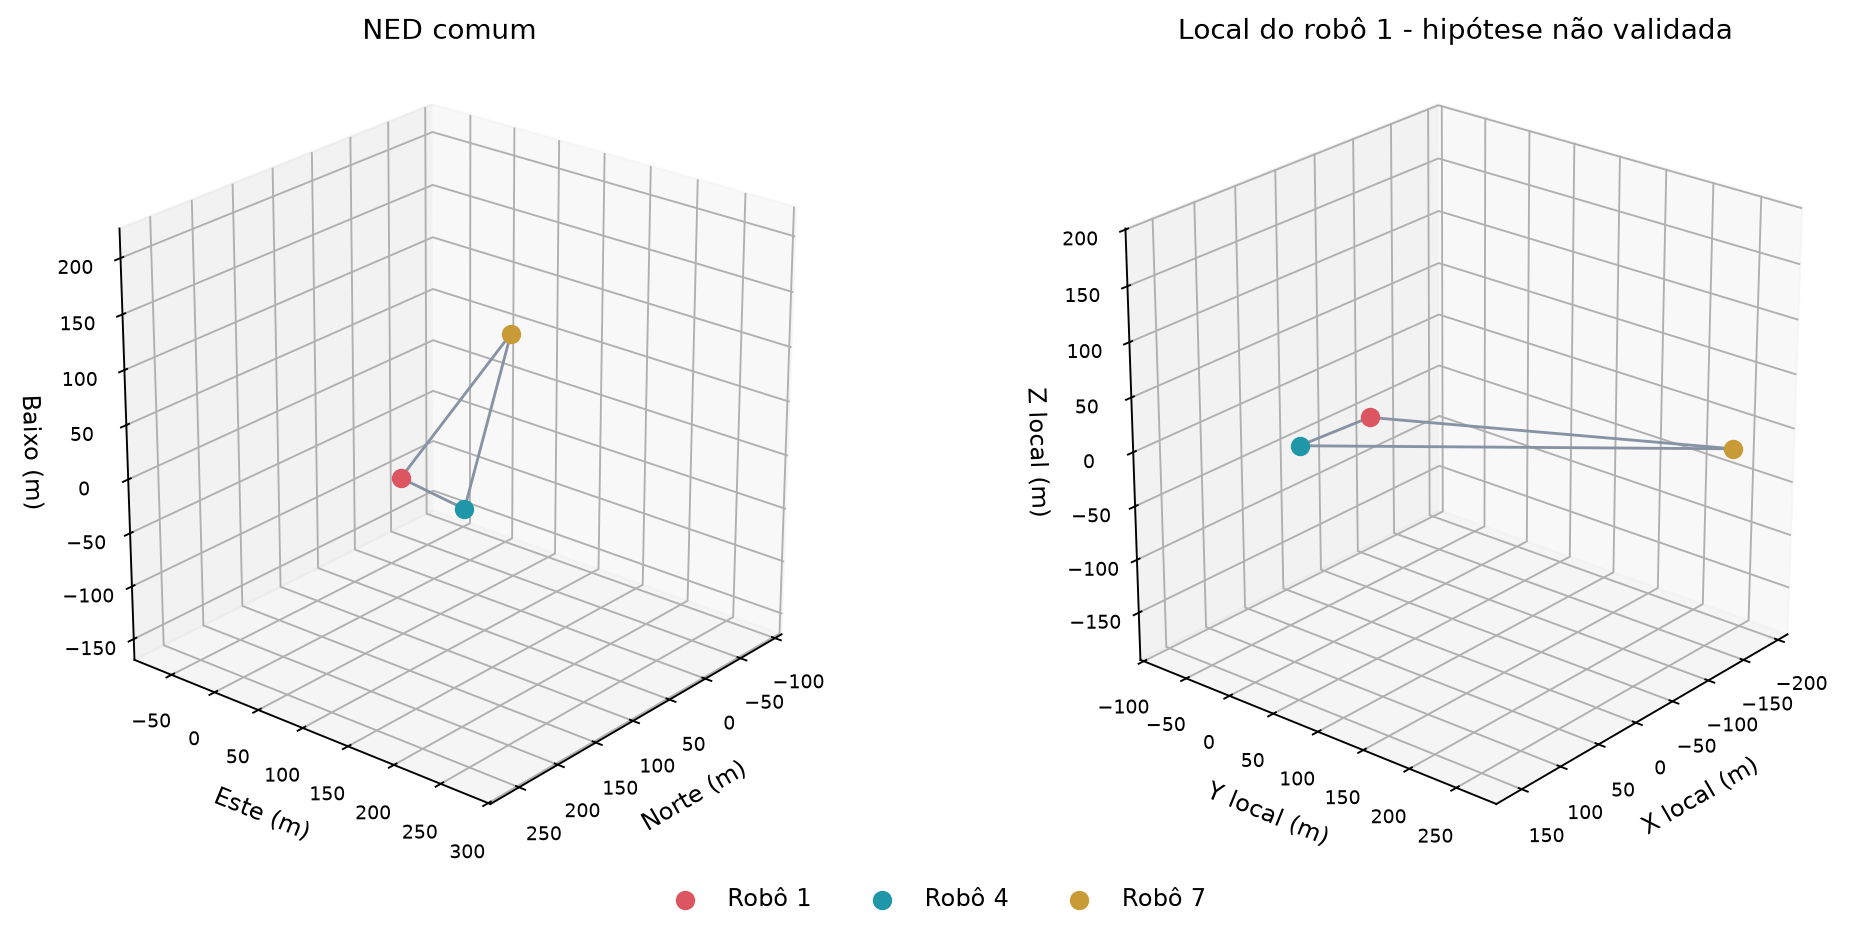

In [6]:
world, local = diagnostic['world'], diagnostic['local']
span = max(np.ptp(world, axis=0).max(), np.ptp(local, axis=0).max())*.65
fig = plt.figure(figsize=(11.8, 5.4), layout='constrained')
for column, points in enumerate([world, local], 1):
    ax = fig.add_subplot(1, 2, column, projection='3d')
    for i, key in enumerate(diagnostic['keys']):
        ax.scatter(*points[i], s=52, color=colors[key], label=mission.traces[key].label)
    for pair in diagnostic['pairs']:
        i, j = [diagnostic['keys'].index(k) for k in pair['robots']]
        edge = points[[i, j]]
        ax.plot(edge[:, 0], edge[:, 1], edge[:, 2], color='#8792a5', linewidth=1.2)
    center = points.mean(axis=0)
    ax.set(xlim=(center[0]-span, center[0]+span), ylim=(center[1]-span, center[1]+span),
           zlim=(center[2]-span, center[2]+span),
           xlabel='Norte (m)' if column == 1 else 'X local (m)',
           ylabel='Este (m)' if column == 1 else 'Y local (m)',
           zlabel='Baixo (m)' if column == 1 else 'Z local (m)',
           title='NED comum' if column == 1 else 'Local do robô 1 - hipótese não validada')
    ax.set_box_aspect((1, 1, 1))
    ax.view_init(elev=24, azim=40)
    ax.tick_params(labelsize=8)
fig.legend(*fig.axes[0].get_legend_handles_labels(), loc='outside lower center', ncol=3, frameon=False)
fig.savefig('tomsa-relatorio-fig2.png', dpi=170, bbox_inches='tight')
plt.show()

**Figura 2.** As mesmas três amostras expressas no NED comum e na base local assumida do robô 1, com escalas métricas iguais nos três eixos e nos dois painéis. As distâncias espaciais coincidem, conforme a tabela; a aparência projetada do triângulo pode mudar. O arredondamento é aplicado apenas na apresentação dos valores.

Neste exemplo, o robô 1 fica na origem local. A distância robô 1-4 é aproximadamente **78,540 m** e a distância robô 1-7 aproximadamente **318,526 m**. Um raio local de 100 m inclui o robô 4 e exclui o robô 7; com 450 m ambos são incluídos. Esta classificação usa a distância 3D, incluindo Down. As tabelas AER dependem do NED relativo, sem utilizar a hipótese de orientação corporal.

### 3.4. Rapidez e variação temporal

A tabela e a Figura 3 usam apenas as amostras dentro do intervalo comum. As unidades seguem a interpretação SI usual declarada no README. A magnitude da aceleração vetorial não é apresentada como medida disponível.

Robô,Mínimo (m/s),Mediana (m/s),P95 (m/s),Máximo (m/s),Aceleração vetorial NED
Robô 1,0.000850,0.482175,0.517956,0.900639,Indisponível
Robô 4,0.004850,0.621053,0.682955,1.063336,Indisponível
Robô 7,0.000646,0.010218,0.028803,0.067335,Indisponível


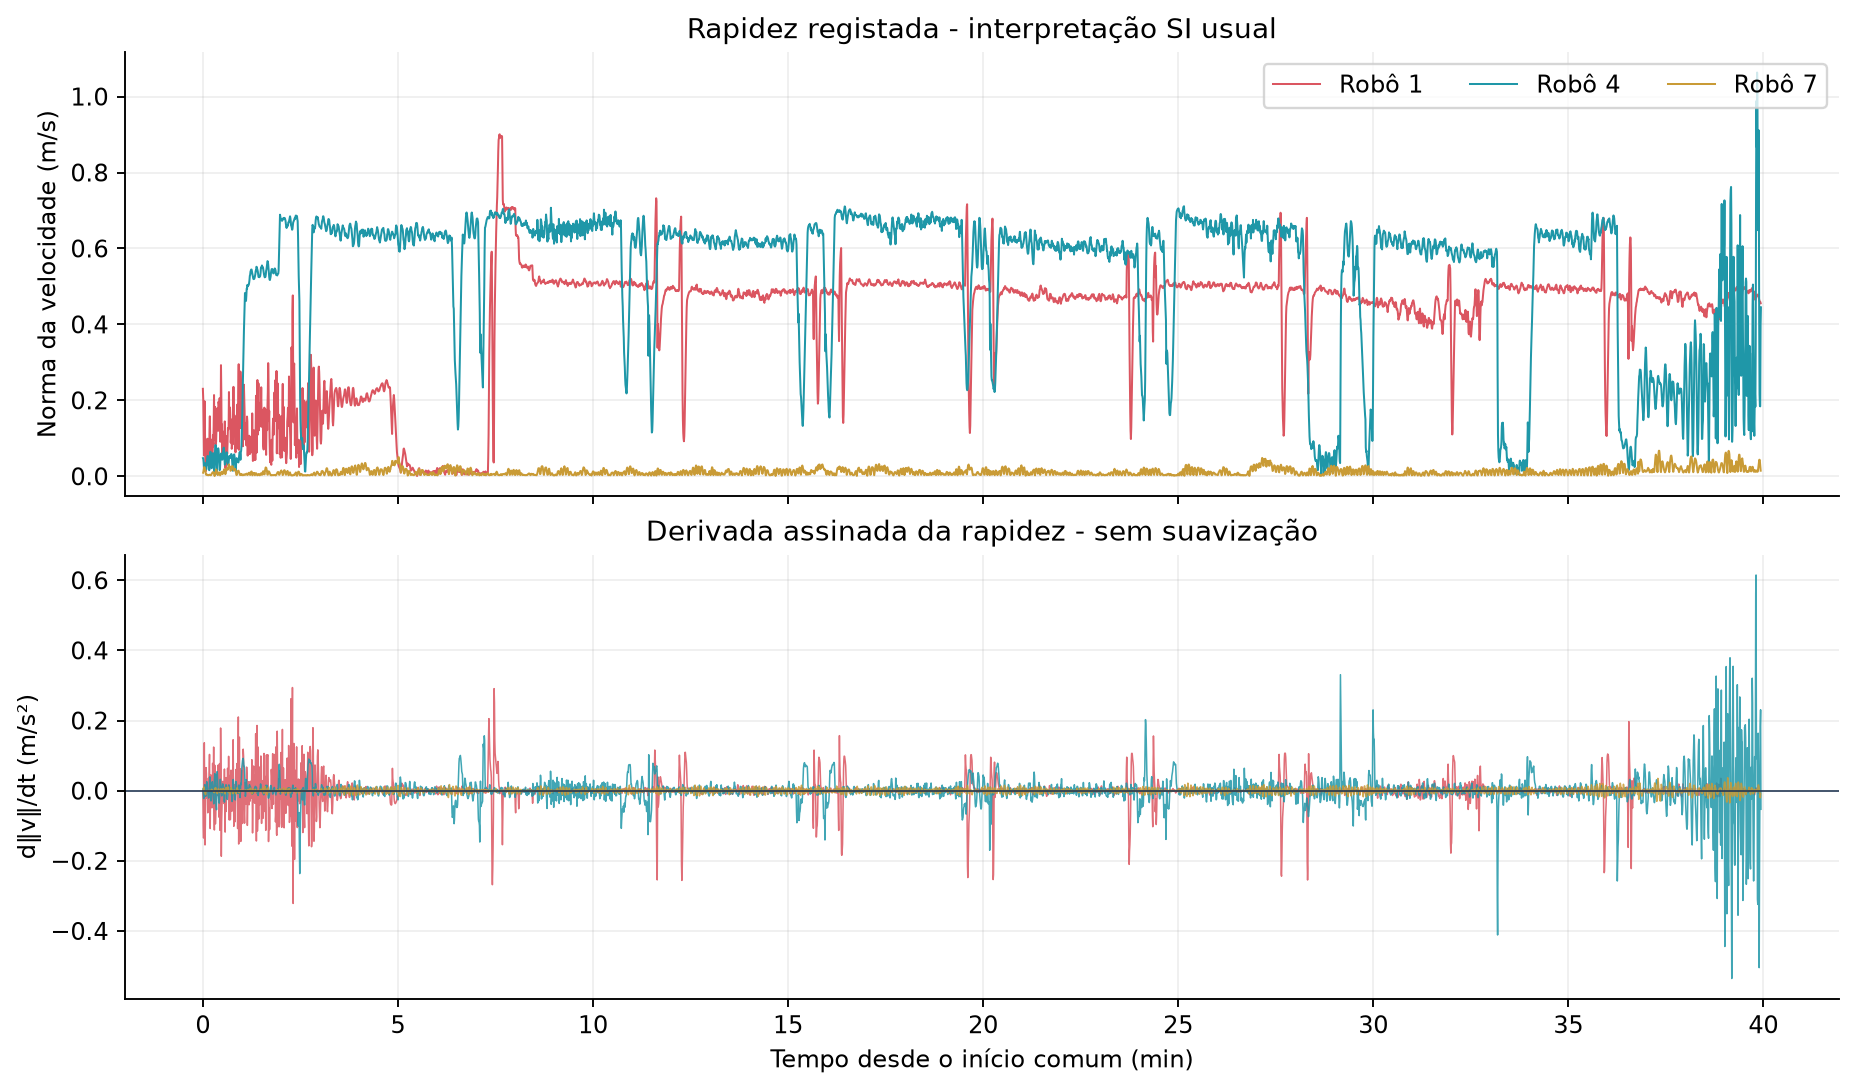

In [7]:
speed_rows = []
for key, trace in mission.traces.items():
    kinematics = trace.kinematics
    speed = kinematics.speed_m_s[masks[key]]
    speed_rows.append({'Robô': trace.label, 'Mínimo (m/s)': np.min(speed),
        'Mediana (m/s)': np.median(speed), 'P95 (m/s)': np.quantile(speed, .95),
        'Máximo (m/s)': np.max(speed), 'Aceleração vetorial NED': 'Indisponível'})
    assert np.isnan(kinematics.acceleration_magnitude_m_s2).all()
tabela(pd.DataFrame(speed_rows), 6)

fig, axes = plt.subplots(2, 1, figsize=(10.8, 6.3), sharex=True, layout='constrained')
for key, trace in mission.traces.items():
    mask = masks[key]
    minutes = (trace.times_ns[mask]-mission.start_ns)/60e9
    axes[0].plot(minutes, trace.kinematics.speed_m_s[mask], color=colors[key],
                 label=trace.label, linewidth=.85)
    axes[1].plot(minutes, trace.kinematics.speed_rate_m_s2[mask], color=colors[key],
                 linewidth=.65, alpha=.85)
axes[0].set(ylabel='Norma da velocidade (m/s)', title='Rapidez registada - interpretação SI usual')
axes[0].legend(ncol=3, loc='upper right')
axes[1].axhline(0, color='#253955', linewidth=.7)
axes[1].set(xlabel='Tempo desde o início comum (min)', ylabel='d‖v‖/dt (m/s²)',
            title='Derivada assinada da rapidez - sem suavização')
fig.savefig('tomsa-relatorio-fig3.png', dpi=170, bbox_inches='tight')
plt.show()

**Figura 3.** Norma da velocidade linear registada e derivada temporal assinada, calculada com os intervalos reais. Não se interpreta a curva inferior como magnitude da aceleração total. Os picos são conservados; não foi aplicado um filtro para os atenuar.

As medianas são aproximadamente **0,482 m/s** no robô 1, **0,621 m/s** no robô 4 e **0,0102 m/s** no robô 7. O valor menor do robô 7 é compatível, em termos qualitativos, com a menor extensão da sua trajetória, mas não demonstra por si só um estado operacional específico. A derivada evidencia transientes e ruído; não foi feita identificação de forças ou de um modelo dinâmico a partir destes gráficos.

### 3.5. Interface e utilização

A Figura 4 foi capturada no dashboard com o modo de dados reais ativo. Mostra a identificação da origem, a seleção do robô, o raio local, Play/Pause e a linha temporal. A aplicação também permite alterar a dimensão das vistas, explorar o mapa, escolher rastos e abrir o painel matemático. O uso do modo real foi verificado pela etiqueta de origem, não apenas pela existência de um servidor numa porta.

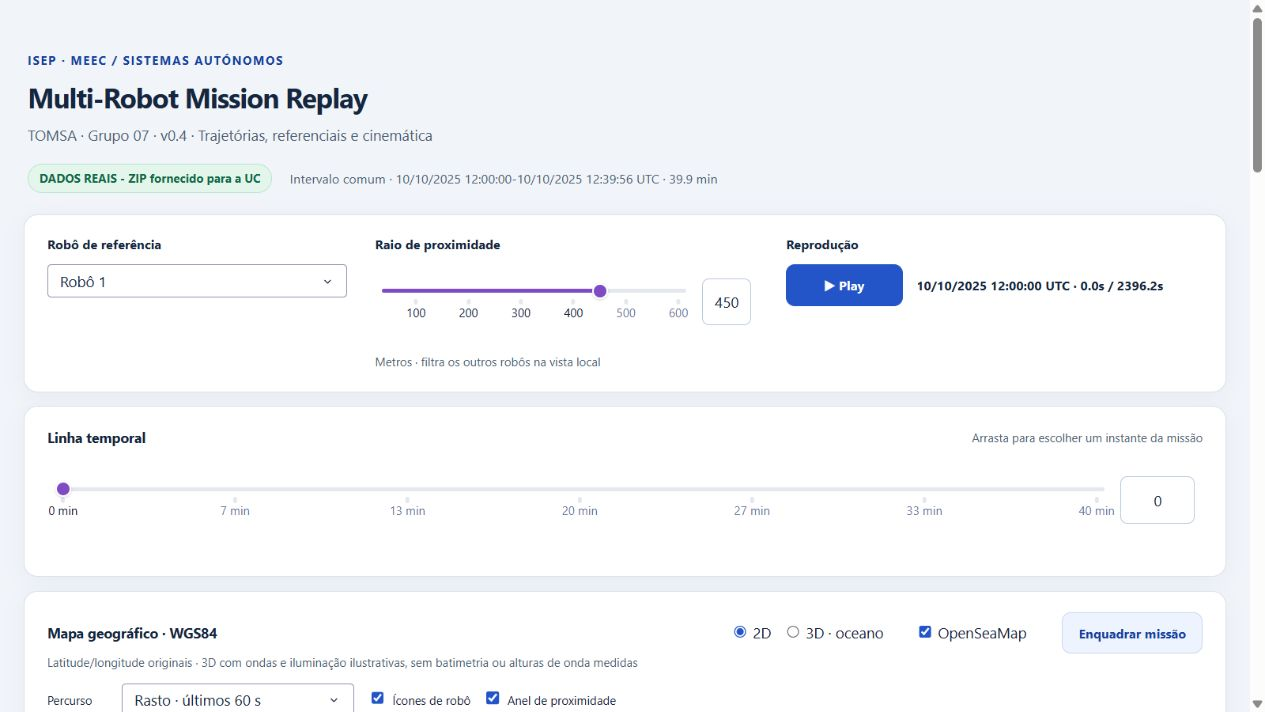

**Figura 4.** Cabeçalho e controlos da aplicação v0.4 com o ZIP real carregado, capturados em 29/10/2026. O indicador de origem distingue os logs da UC da demo sintética.

Para iniciar a aplicação, na pasta `TOMSA_Grupo07_v03`, executar `python app.py` e abrir `http://127.0.0.1:8050`. O YAML fornecido usa `data.mode: zip`; `--demo` ativa explicitamente dados sintéticos. O servidor é local. O mapa requer WebGL e acesso ao CDN/provedores de mosaicos; as vistas cartesianas continuam utilizáveis se a cartografia falhar. As ondas do mapa são um efeito visual e não fazem parte das evidências físicas da missão.

### 3.6. Testes e rastreabilidade

A execução seguinte verifica a versão atual do projeto. Inclui exemplos de rotação conhecida, ida e volta, quaterniões equivalentes, preservação de distâncias 3D, AER, timestamps, lacunas, derivadas em malha não uniforme, estados de confirmação, serialização de callbacks e exportações. Quando Node está disponível, pytest também executa os testes JavaScript do ciclo do mapa, rastos e oceano com objetos simulados, sem pedidos de mosaicos.

In [8]:
result = subprocess.run([sys.executable, '-m', 'pytest', '-q'], cwd=PROJECT_DIR,
                        capture_output=True, text=True, encoding='utf-8', errors='replace')
print(result.stdout.strip())
if result.returncode:
    print(result.stderr)
assert result.returncode == 0, 'Existem testes com falhas; rever antes de entregar.'
tabela(pd.DataFrame([{'Componente': name, 'Versao usada': importlib.metadata.version(name)}
    for name in ['numpy', 'pandas', 'scipy', 'plotly', 'dash', 'PyYAML', 'matplotlib', 'pytest']]))
print('SHA-256 do ZIP utilizado: ' + hashlib.sha256(zip_path.read_bytes()).hexdigest())

............................................................             [100%]
60 passed in 8.58s


Componente,Versao usada
numpy,2.5.4
pandas,3.0.6
scipy,1.18.1
plotly,7.1.0
dash,4.4.1
PyYAML,6.0.3
matplotlib,3.11.2
pytest,9.1.1


SHA-256 do ZIP utilizado: 50eba985260ea849f8d5762086b2a352f0bd88ec6c6cc6469fb2f2365e3bafa1


O resultado obtido nesta revisão foi **60 testes aprovados**, incluindo os testes com o ZIP real disponível. Este número corresponde aos casos pytest; os subtestes JavaScript executados por esses casos não devem ser somados como se fossem testes pytest adicionais. A auditoria dos 14 382 diagnósticos é apresentada separadamente na secção 3.2.

Os testes com rotações conhecidas verificam comportamento que os logs, por si só, não poderiam validar. A preservação de distâncias em dados reais acrescenta uma verificação de consistência, mas não valida a convenção física. Foi também verificado no browser o carregamento da origem real e dos controlos; na revisão funcional da aplicação foram exercitados o painel matemático, a procura temporal e os efeitos do mapa. Estes ensaios de desktop não substituem testes em todos os browsers, dispositivos ou condições de rede.

### 3.7. Limitações e trabalho futuro

- **Convenções externas por confirmar:** datum vertical, eixos/sentido dos quaterniões, base das velocidades e sincronização dos relógios. `world_ned`, `WGS84` e `body` não resolvem estas questões automaticamente.
- **Amostragem e ruído:** a política de amostra mais próxima pode introduzir diferenças temporais entre robôs. Não foi aplicada interpolação ou suavização; as derivadas amplificam ruído.
- **Incerteza:** as covariâncias fornecidas não foram propagadas através das transformações, nem usadas para desenhar regiões de confiança. Os erros numéricos apresentados não são erros de medição.
- **Cartografia e apresentação:** dependência de rede/WebGL para o mapa, círculo horizontal aproximado e oceano ilustrativo. Não há batimetria, estado do mar medido ou certificação para navegação.
- **Validação física:** não dispomos de trajetória de referência independente para medir erro de localização. Os resultados demonstram coerência matemática e funcionalidade do visualizador, não desempenho de um sistema de estimação.

A prioridade seguinte é obter confirmação documental das convenções. Só depois faria sentido ativar interpretações corporais confirmadas e aceleração vetorial nos logs reais. A propagação de covariâncias, uma política de interpolação justificada e validação com referência independente seriam extensões úteis, mantendo sempre separadas as amostras originais e as estimativas adicionais.

<a id="equipa"></a>
## 4. Análise crítica do trabalho da equipa

[Voltar ao conteúdo](#conteudo)

O resultado permite avaliar a integração de três áreas: leitura e compreensão dos dados, formulação matemática e desenvolvimento da interface. A separação destas responsabilidades em módulos facilita rever alterações e discutir um cálculo sem depender do aspeto do dashboard. Os exemplos simples e os testes automatizados fornecem uma base comum para preparar a defesa.

A participação foi repartida pelas três áreas. O Francisco teve maior intervenção na ideação, o Pedro no código e o Henrique na documentação. Todos contribuíram também nas restantes componentes, ajudando na revisão e na integração do trabalho. A tabela apresenta uma estimativa equilibrada dessa participação, e não uma contagem de horas.

O aspeto mais conseguido é a ligação entre a mudança de referencial e evidências verificáveis: a origem local, a inversa e as distâncias podem ser inspecionadas nas mesmas amostras que aparecem no replay. A preservação das cores, do instante selecionado e dos estados de indisponibilidade também melhora a compreensão. As extensões visuais tornam a exploração mais apelativa, mas a sua utilidade depende de continuarem identificadas como apresentação.

O principal ponto a melhorar é fechar as questões do produtor dos dados logo na fase inicial. Ter identificado os campos não substituiu confirmar os eixos, unidades e datum. Enquanto esses pontos permanecerem abertos, parte da orientação e da cinemática só pode ser tratada condicionalmente. Também seria útil formalizar uma lista de aceitação que associasse cada requisito a um teste e a uma demonstração curta, e ampliar os ensaios gráficos para mais dispositivos.

Para a apresentação, todos os elementos devem conseguir explicar a diferença entre coordenadas geodésicas e NED, a expressão $p_L=R^T(p_N-p_0)$, a escolha temporal e a diferença entre $ds/dt$ e aceleração total. Uma defesa consistente exige conhecer estas decisões e limites, além de saber operar a interface.

**Tabela 1. Avaliação individual do grupo**

| N.º | Nome | Ideação (%) | Código (%) | Documentação (%) | Total (%) |
|---|---|---:|---:|---:|---:|
| 1221309 | Henrique Correia | 30 | 30 | 40 | 33,33 |
| 1231177 | Pedro Ribeiro | 30 | 40 | 30 | 33,34 |
| 1231216 | Francisco Liquito | 40 | 30 | 30 | 33,33 |
| | Total | 100 | 100 | 100 | 100 |

O total foi calculado pela média das três componentes, com igual peso. O contributo global corresponde a um terço para cada elemento; o ajuste de 0,01 ponto percentual na apresentação serve apenas para que a soma seja exatamente 100% após o arredondamento.

<a id="referencias"></a>
## Referências

[1] Pedro Barbosa Guedes. *TL- TOMSA - 2026.pdf*. Enunciado da UC: funcionalidades (slide 2), referenciais ECEF/NED/AER (slides 3-5) e critérios da segunda entrega (slide 7).

[2] *TOMSA2026_TL_readme.pdf*, incluído no arquivo `TL2026.zip`. Estrutura dos logs, restrições de utilização e referência inicial da missão, pp. 1-2.

[3] Grupo 07. *TOMSA_TL1_GRUPO07.ipynb*. Primeira entrega: objetivos, seleção de bibliotecas, análise inicial e metodologia proposta.

[4] SciPy. [Rotation.from_quat](https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.transform.Rotation.from_quat.html). Ordem dos componentes e representação de rotações.

[5] NumPy. [numpy.gradient](https://numpy.org/doc/stable/reference/generated/numpy.gradient.html). Diferenciação numérica com espaçamento uniforme ou não uniforme.

[6] Plotly Dash. [Basic Callbacks](https://dash.plotly.com/basic-callbacks). Relação entre propriedades de entrada, funções e saídas da interface.

[7] PROJ. [Geocentric to topocentric conversion](https://proj.org/en/stable/operations/conversions/topocentric.html). Conversão de coordenadas geocêntricas para uma base local tangente.

[8] Grupo 07. Código da aplicação v0.4, `README.md`, `config.yaml` e testes na pasta `TOMSA_Grupo07_v03`. Versão local consultada e executada para esta entrega.

Documentação online verificada em 29 de outubro de 2026. As figuras 1-3 foram calculadas com os dados reais e as funções do projeto; a Figura 4 é uma captura da aplicação. Não foram usadas trajetórias sintéticas como evidência dos resultados da missão.